# Demand Shock and Price Discovery

Recreates a controlled demand increase in a seven-period BSE market. The saved figure places the supply and demand schedules beside the transaction-price response. Running the code starts one market session and temporarily writes a tape CSV.


Simulation started: smith_exp...
Simulation completed.
Trades/period: [0, 32, 31, 32, 32, 39, 35]


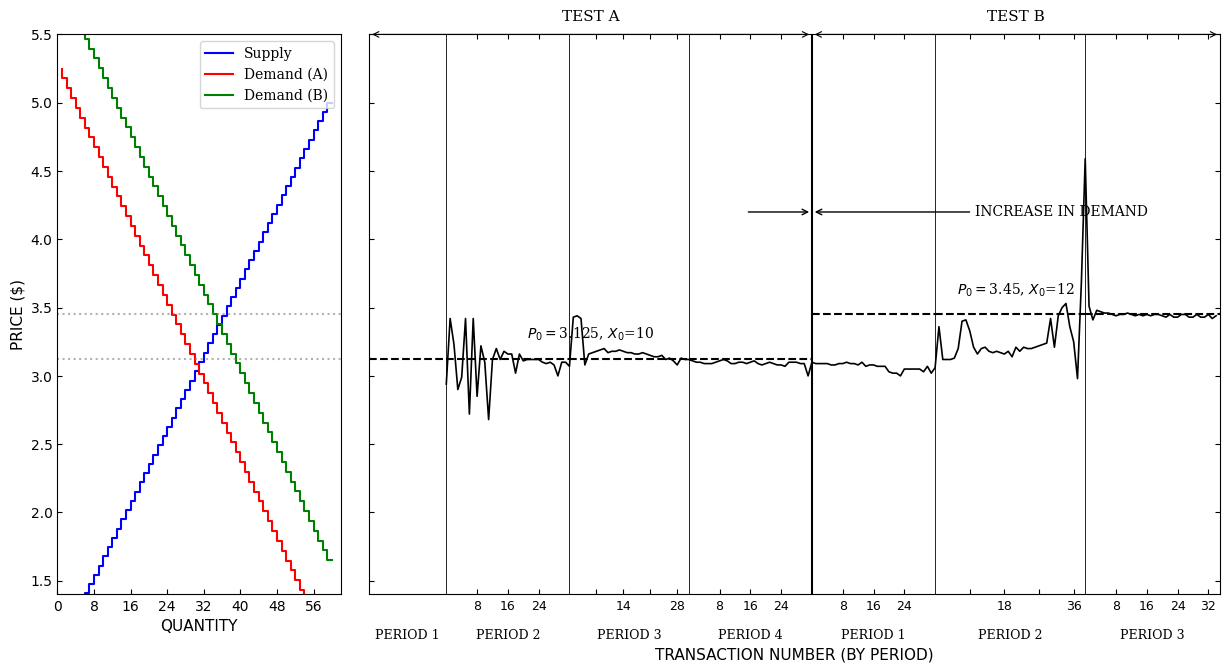

In [ ]:
import bse
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np
import csv
import os

# Set price limits for the simulated market.
bse.bse_sys_maxprice = 600  
bse.bse_sys_minprice = 90

n_A = 4
n_B = 3
n_total_prd = n_A + n_B

dur = 300 

t_start = 0
t_mid = n_A * dur
t_end = n_total_prd * dur

sched_sup = [{'from': t_start, 'to': t_end, 'ranges': [(100, 500)], 'stepmode': 'fixed'}]

# Increase demand after period four.
sched_dem_A = [{'from': t_start, 'to': t_mid, 'ranges': [(100, 525)], 'stepmode': 'fixed'}]
sched_dem_B = [{'from': t_mid, 'to': t_end, 'ranges': [(165, 590)], 'stepmode': 'fixed'}]
sched_dem = sched_dem_A + sched_dem_B

order_sched = {
    'sup': sched_sup, 
    'dem': sched_dem, 
    'interval': dur, 
    'timemode': 'periodic'
}


n_zip = 20
n_shvr = 20
n_zic = 20

# Sixty traders on each side of the market.
n_side = n_zip + n_shvr + n_zic

sellers = [('ZIP', n_zip), ('SHVR', n_shvr), ('ZIC', n_zic)]
buyers  = [('ZIP', n_zip), ('SHVR', n_shvr), ('ZIC', n_zic)]

traders = {'sellers': sellers, 'buyers': buyers}

sess_id = 'smith_exp'
flags = {
    'dump_blotters': False, 
    'dump_lobs': False, 
    'dump_strats': False,
    'dump_avgbals': False, 
    'dump_tape': True
}

print(f"Simulation started: {sess_id}...")
bse.market_session(sess_id, t_start, t_end, traders, order_sched, flags, False)
print("Simulation completed.")

fname = f'{sess_id}_tape.csv'
trades = [] 

try:
    with open(fname, 'r') as f:
        reader = csv.reader(f)
        for row in reader:
            if row[0] == 'Trd':
                t = float(row[1])
                p = float(row[2]) / 100.0  
                trades.append((t, p))
    # clean
    os.remove(fname) 

except FileNotFoundError:
    print(f"Error: {fname} not found.")
    exit()

# Group trades by market period.
buckets = [[] for _ in range(n_total_prd)]

for t, p in trades:
    idx = int(t / dur)
    if idx >= n_total_prd:
        idx = n_total_prd - 1
    buckets[idx].append(p)

print(f"Trades/period: {[len(b) for b in buckets]}")


def gen_steps(min_p, max_p, n):
    return np.linspace(min_p, max_p, n) / 100.0

n_step = n_side 

sup_line = gen_steps(100, 500, n_step)
dem_line_A = sorted(gen_steps(100, 525, n_step), reverse=True)
dem_line_B = sorted(gen_steps(165, 590, n_step), reverse=True)
q_grid = np.arange(1, n_step + 1)

eq_p_A = 3.125
eq_p_B = 3.45
eq_q_A = 10 
eq_q_B = 12 

# Plot the market schedules and transaction prices.
plt.style.use('default')
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 8), sharey=True, gridspec_kw={'width_ratios': [1, 3]})
plt.subplots_adjust(wspace=0.05, bottom=0.2, top=0.9) 
plt.rcParams['font.family'] = 'serif'

# Supply and demand schedules.
ax1.step(q_grid, sup_line, where='pre', color='blue', lw=1.5, label='Supply')
ax1.step(q_grid, dem_line_A, where='pre', color='red', lw=1.5, label='Demand (A)')
ax1.step(q_grid, dem_line_B, where='pre', color='green', lw=1.5, label='Demand (B)')

ax1.legend(loc='upper right', fontsize=10, framealpha=0.8)
ax1.axhline(y=eq_p_A, color='gray', ls=':', alpha=0.6)
ax1.axhline(y=eq_p_B, color='gray', ls=':', alpha=0.6)

ax1.set_ylim(1.40, 5.50)
ax1.set_xlim(0, n_step + 2)
ax1.set_ylabel('PRICE ($)', fontsize=11)
ax1.set_xlabel('QUANTITY', fontsize=11)
ax1.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))
ax1.tick_params(direction='in')

# Transaction-price series.
cur_x = 0
xticks = []
xlabels = []
shock_x = 0

plot_x = []
plot_y = []

for i, prices in enumerate(buckets):
    n = len(prices)
    w = n if n > 0 else 20  # wide
    
    seg_x = list(range(cur_x, cur_x + w))
    
    if n > 0:
        plot_x.extend(seg_x)
        plot_y.extend(prices)
    
    # Plot the theoretical equilibrium for each period.
    is_A = i < n_A
    eq = eq_p_A if is_A else eq_p_B
    ax2.hlines(y=eq, xmin=cur_x, xmax=cur_x + w, colors='black', ls='--', lw=1.5)

    # Separate market periods.
    ax2.axvline(x=cur_x + w, color='black', ls='-', lw=0.6)

    mid = cur_x + w / 2
    p_idx = (i + 1) if is_A else (i + 1 - n_A)
    ax2.text(mid, -0.08, f"PERIOD {p_idx}", ha='center', fontsize=9, 
             transform=ax2.get_xaxis_transform(), clip_on=False)
    
    # Add transaction-number labels within each period.
    if n > 0:
        step = max(2, int(w / 4))
        for k in range(step, w, step):
            xticks.append(cur_x + k)
            xlabels.append(str(k) if k % 2 == 0 else "")
    
    if i == n_A - 1:
        shock_x = cur_x + w

    cur_x += w

if plot_x:
    ax2.plot(plot_x, plot_y, color='black', lw=1.2)

ax2.axvline(x=shock_x, color='black', lw=1.5)

ax2.set_xticks(xticks)
ax2.set_xticklabels(xlabels, fontsize=9)
ax2.set_xlabel('TRANSACTION NUMBER (BY PERIOD)', fontsize=11, labelpad=25)
ax2.set_xlim(0, cur_x)
ax2.tick_params(direction='in', top=True, right=True)
plt.setp(ax2.get_yticklabels(), visible=False)

mid_A = shock_x / 2
mid_B = (shock_x + cur_x) / 2

ax2.text(mid_A, 5.6, "TEST A", ha='center', fontsize=11)
ax2.text(mid_B, 5.6, "TEST B", ha='center', fontsize=11)

# Mark the demand shock.
ax2.annotate('', xy=(0, 5.5), xytext=(shock_x, 5.5), arrowprops=dict(arrowstyle='<->', lw=0.8))
ax2.annotate('', xy=(shock_x, 5.5), xytext=(cur_x, 5.5), arrowprops=dict(arrowstyle='<->', lw=0.8))

ax2.annotate('INCREASE IN DEMAND', xy=(shock_x, 4.2), xytext=(shock_x + (cur_x-shock_x)*0.4, 4.2),
             arrowprops=dict(arrowstyle='->', lw=1.0), fontsize=10, va='center')
ax2.annotate('', xy=(shock_x, 4.2), xytext=(shock_x - (shock_x)*0.15, 4.2),
             arrowprops=dict(arrowstyle='->', lw=1.0))

# Label the equilibrium price and quantity.
ax2.text(mid_A, eq_p_A + 0.15, f'$P_0=${eq_p_A:.3f}, $X_0$={eq_q_A}', ha='center', fontsize=10)
ax2.text(mid_B, eq_p_B + 0.15, f'$P_0=${eq_p_B:.2f}, $X_0$={eq_q_B}', ha='center', fontsize=10)

plt.show()